# Alcohol use among secondary school students: *who drinks, and can we predict it?*

**Three questions:**
1. *Descriptive*: who are the students who drink? Is there a difference between weekdays and weekends?
2. *Structure*: is drinking part of a particular lifestyle? (PCA)
3. *Prediction*: can we predict heavy drinking from the social, family and behavioural profile, and what are the risk factors?

**Methods**: descriptive statistics + χ² test, PCA, discriminant analysis (LDA/QDA), logistic regression, KNN, gradient boosting (scikit-learn and skrub), and a short *k*-means typology.

## 1. Imports and data loading

The *Student Alcohol Consumption* dataset has two files (maths and Portuguese). The **Portuguese class is the main sample** because it is larger (649 students vs 395): more statistical power. The maths class is used as a **robustness check** (section 9).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid", context="notebook")
RNG = 0  # seed for reproducibility


por = pd.read_csv("../data/student-por.csv")   # main sample (n = 649)
mat = pd.read_csv("../data/student-mat.csv")   # robustness sample (n = 395)

print("Portuguese:", por.shape, " | Maths:", mat.shape)
print("Missing values (Portuguese):", int(por.isna().sum().sum()))
por.head()

Portuguese: (649, 33)  | Maths: (395, 33)
Missing values (Portuguese): 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
# Variable groups reused throughout the notebook
# Numerical variables (quantitative or ordinal)
NUM = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures",
       "famrel", "freetime", "goout", "health", "absences"]

# Categorical variables (nominal or binary)
CAT = ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
       "reason", "guardian", "schoolsup", "famsup", "paid", "activities",
       "nursery", "higher", "internet", "romantic"]

print(f"{len(NUM)} numerical variables, {len(CAT)} categorical variables "
      f"(Dalc, Walc and the grades G1/G2/G3 are excluded)") # grades = an outcome, not a cause

11 numerical variables, 17 categorical variables (Dalc, Walc and the grades G1/G2/G3 are excluded)


## 2. Defining the target

Alcohol use is measured by two ordinal variables from 1 (very low) to 5 (very high): `Dalc` (weekdays) and `Walc` (weekend).

To turn this into a **classification** problem, we define a binary target **`high` = heavy weekend drinking (`Walc` ≥ 4)**. This threshold isolates about **20% of the students**: a clear minority, but not too rare.

We keep this **imbalance** in mind: models are judged on **ROC AUC** and **F1**, not only on *accuracy* (a trivial model already reaches ~80%).

In [3]:
def add_target(df, threshold=4):
    """Add the binary column 'high' = heavy weekend drinking (Walc >= threshold)."""
    out = df.copy()
    out["high"] = (out["Walc"] >= threshold).astype(int)
    return out

por = add_target(por)
mat = add_target(mat)

counts = por["high"].value_counts().rename({0: "low/moderate", 1: "heavy drinking"})
print("Distribution of the target 'high' (Walc >= 4), Portuguese:")
print(counts.to_string())
print(f"\nShare of heavy drinkers: {por['high'].mean():.1%}  (n = {int(por['high'].sum())})")

Distribution of the target 'high' (Walc >= 4), Portuguese:
high
low/moderate      517
heavy drinking    132

Share of heavy drinkers: 20.3%  (n = 132)


## 3. Descriptive analysis: who drinks?

Goal: spot the variables linked to drinking by eye, before any modelling.

### 3.1 Weekday vs weekend distribution

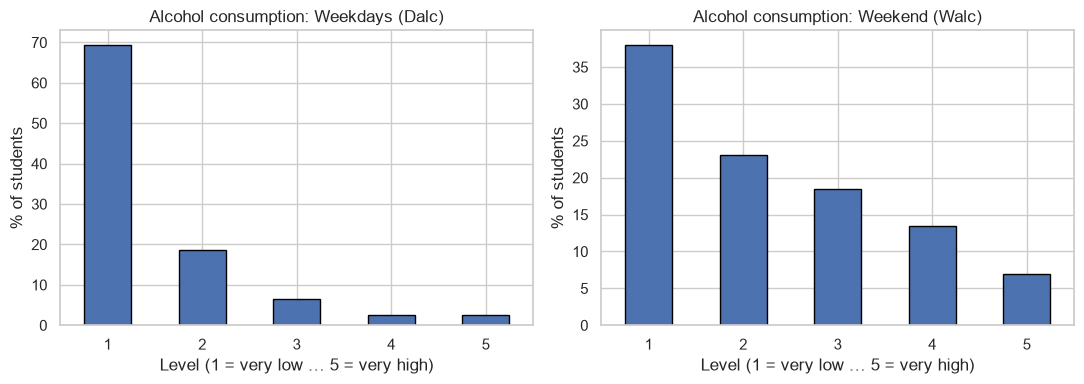

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["Dalc", "Walc"],
                          ["Weekdays (Dalc)", "Weekend (Walc)"]):
    (por[col].value_counts(normalize=True).sort_index() * 100).plot(
        kind="bar", ax=ax, color="#4C72B0", edgecolor="black")
    ax.set_title(f"Alcohol consumption: {title}")
    ax.set_xlabel("Level (1 = very low … 5 = very high)")
    ax.set_ylabel("% of students")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

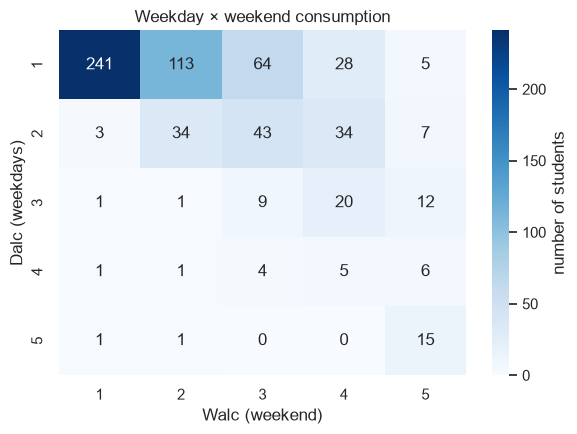

Spearman correlation Dalc–Walc: 0.613 → related but distinct


In [5]:
# Are the two variables redundant? Cross weekdays x weekend.
ct = pd.crosstab(por["Dalc"], por["Walc"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "number of students"})
plt.title("Weekday × weekend consumption")
plt.xlabel("Walc (weekend)"); plt.ylabel("Dalc (weekdays)")
plt.tight_layout(); plt.show()

print("Spearman correlation Dalc–Walc:",
      round(por["Dalc"].corr(por["Walc"], method="spearman"), 3),
      "→ related but distinct")

### 3.2 Link with categorical variables (χ² test)

The χ² test of independence checks whether the heavy/light split differs across the levels of a categorical variable. A *p-value* < 5% indicates a statistically significant association.

In [6]:
def chi2_table(df, target, variables):
    """χ² test of independence between 'target' (binary) and each categorical variable."""
    rows = []
    for v in variables:
        table = pd.crosstab(df[v], df[target])
        chi2, p, dof, _ = chi2_contingency(table)
        rows.append({"variable": v, "chi2": round(chi2, 2), "p_value": p,
                     "significant (5%)": "yes" if p < 0.05 else "no"})
    return pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)

cat_to_test = ["sex", "address", "romantic", "Pstatus", "activities",
               "higher", "schoolsup", "internet", "famsup"]
chi2_table(por, "high", CAT)

,variable,chi2,p_value,significant (5%)
0,sex,64.17,1.142752e-15,yes
1,famsup,6.21,1.267223e-02,yes
2,higher,2.99,8.375283e-02,no
3,famsize,2.53,1.114754e-01,no
4,nursery,2.51,1.130292e-01,no
5,paid,2.14,1.431971e-01,no
6,Fjob,6.53,1.629252e-01,no
7,schoolsup,1.90,1.679271e-01,no
8,activities,1.58,2.094553e-01,no
9,reason,3.94,2.685644e-01,no


Variables significant at 5%:
 variable      chi2      p_value
    goout 89.193293 1.953689e-18
      sex 64.167555 1.142752e-15
 absences 36.678342 3.512460e-02
studytime 35.562777 9.264314e-08
 freetime 10.546078 3.216816e-02
   famsup  6.214303 1.267223e-02


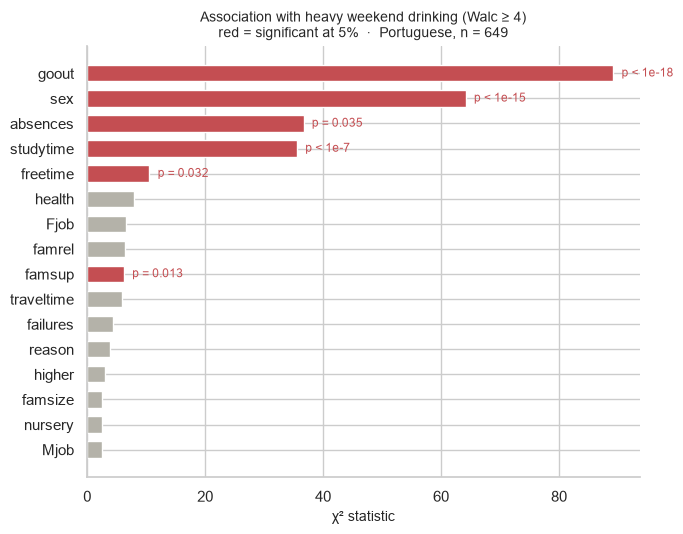

In [7]:
# Extended χ²: categorical + ordinal variables (goout, studytime…)
# goout and studytime are in NUM (ordinal), so they are missing from chi2_table above.
# Here they are treated as categorical: this is valid because the χ² test assumes no linearity,
# it only tests independence between the levels and the target.

ORDINAL_CATS = ["goout", "studytime", "freetime", "famrel",
                "health", "failures", "traveltime", "absences"]

rows_ext = []
for v in CAT + ORDINAL_CATS:
    table = pd.crosstab(por[v], por["high"])
    stat, p, dof, _ = chi2_contingency(table)
    rows_ext.append({"variable": v, "chi2": stat, "p_value": p})

chi2_full = (pd.DataFrame(rows_ext)
             .sort_values("chi2", ascending=False)
             .reset_index(drop=True))

print("Variables significant at 5%:")
print(chi2_full[chi2_full["p_value"] < 0.05][["variable", "chi2", "p_value"]]
      .to_string(index=False))

# ── Figure ────────────────────────────────────────────────────────────────────
top = chi2_full.head(16).iloc[::-1]          # top 16, ascending order for barh
sig = top["p_value"] < 0.05

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top["variable"], top["chi2"],
        color=["#C44E52" if s else "#B4B2A9" for s in sig],
        height=0.65, edgecolor="white")

for _, row in top.iterrows():
    if row["p_value"] < 0.05:
        exp = int(round(-np.log10(row["p_value"])))
        label = f"  p < 1e-{exp}" if row["p_value"] < 0.001 else f"  p = {row['p_value']:.3f}"
        ax.text(row["chi2"] + 0.4, row["variable"], label,
                va="center", ha="left", fontsize=8.5, color="#C44E52")

ax.set_xlabel("χ² statistic", fontsize=10)
ax.set_title("Association with heavy weekend drinking (Walc ≥ 4)\n"
             "red = significant at 5%  ·  Portuguese, n = 649", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

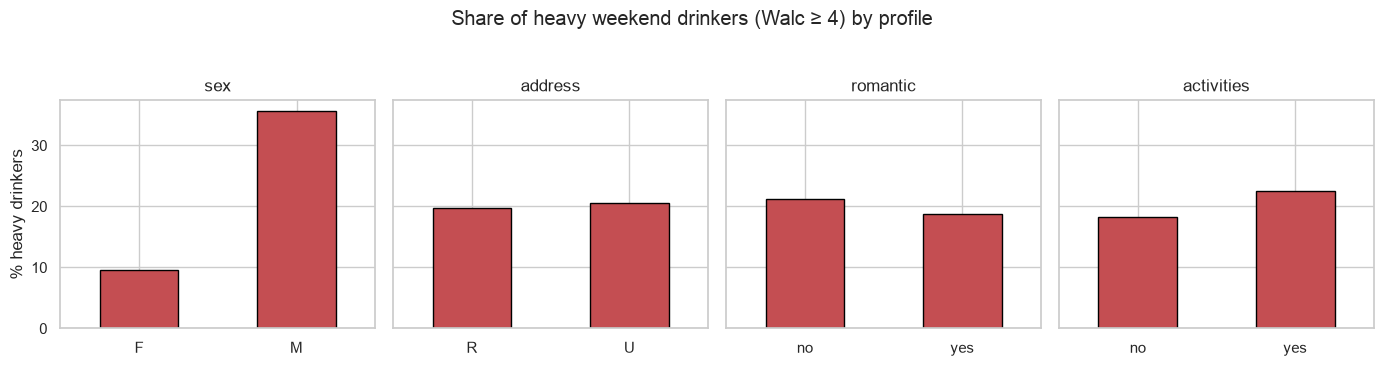

In [8]:
# Share of heavy drinkers (Walc >= 4) by profile
vars_plot = ["sex", "address", "romantic", "activities"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, v in zip(axes, vars_plot):
    (por.groupby(v)["high"].mean() * 100).plot(
        kind="bar", ax=ax, color="#C44E52", edgecolor="black")
    ax.set_title(v); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("% heavy drinkers")
plt.suptitle("Share of heavy weekend drinkers (Walc ≥ 4) by profile", y=1.04)
plt.tight_layout(); plt.show()

### 3.3 Link with numerical variables

How going out (`goout`), study time (`studytime`), absences and free time vary with the level of weekend drinking.

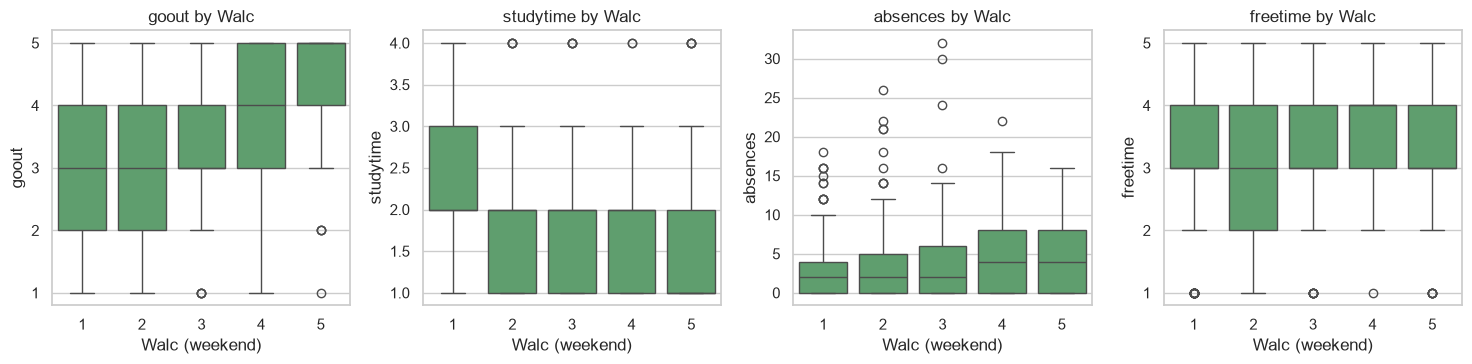

In [9]:
quant_vars = ["goout", "studytime", "absences", "freetime"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, v in zip(axes, quant_vars):
    sns.boxplot(data=por, x="Walc", y=v, ax=ax, color="#55A868")
    ax.set_title(f"{v} by Walc"); ax.set_xlabel("Walc (weekend)")
plt.tight_layout(); plt.show()

## 4. PCA: is drinking part of a lifestyle?

We run a **Principal Component Analysis** on the numerical variables **excluding alcohol**. If heavy drinkers cluster in one area of the factor plane, their drinking is tied to a particular lifestyle.

### 4.1 Explained variance and correlation circle

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_pca = por[NUM].copy()                       # numerical block, without alcohol
Xz = StandardScaler().fit_transform(X_pca)

pca = PCA(n_components=5, random_state=RNG)
scores = pca.fit_transform(Xz)
var = pca.explained_variance_ratio_ * 100

print("Explained variance per component (%):", np.round(var, 1))
print(f"Cumulative on the first 2: {var[:2].sum():.1f} %")

Explained variance per component (%): [18.1 13.6 11.8  9.7  9.2]
Cumulative on the first 2: 31.7 %


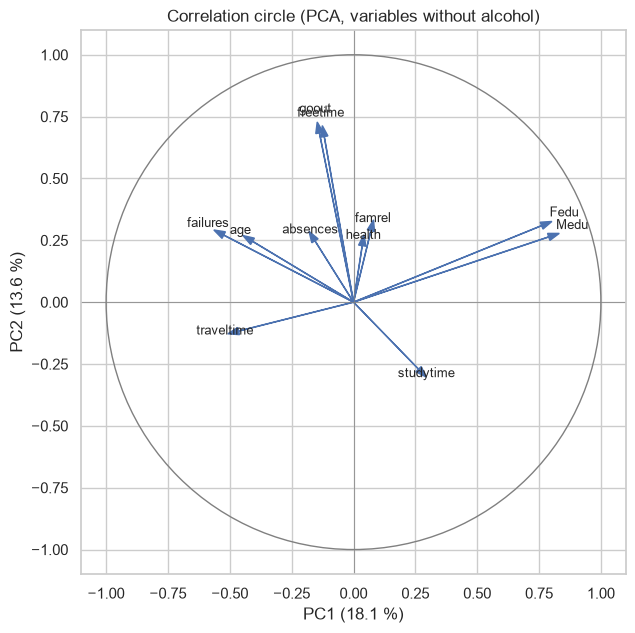

In [11]:
# Correlation circle: a variable's coordinate = its correlation with the component
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for i, v in enumerate(NUM):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1], head_width=0.03, color="#4C72B0")
    ax.text(loadings[i, 0] * 1.12, loadings[i, 1] * 1.12, v, ha="center", fontsize=9)
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({var[0]:.1f} %)"); ax.set_ylabel(f"PC2 ({var[1]:.1f} %)")
ax.set_title("Correlation circle (PCA, variables without alcohol)")
plt.tight_layout(); plt.show()

In [12]:
# Correlation of each variable with the first two PCA axes.
# On standardised data, the loadings are exactly the variable–component correlations.
corr_axes = pd.DataFrame(
    pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]),
    index=NUM,
    columns=[f"PC1 ({var[0]:.1f} %)", f"PC2 ({var[1]:.1f} %)"],
).round(3)

# Sort by correlation with PC1 (most negative to most positive)
corr_axes = corr_axes.sort_values(corr_axes.columns[0])
corr_axes.style.background_gradient(cmap="coolwarm", axis=None, vmin=-1, vmax=1).format("{:.2f}")

,PC1 (18.1 %),PC2 (13.6 %)
failures,-0.53,0.27
traveltime,-0.46,-0.12
age,-0.41,0.25
absences,-0.16,0.25
goout,-0.14,0.68
freetime,-0.12,0.67
health,0.04,0.23
famrel,0.07,0.29
studytime,0.26,-0.27
Fedu,0.76,0.31


**Reading the axes.** PC1 is the axis of school and family background: on the right, students from a more educated family on a good track; on the left, students with failures or who are behind. PC2 is the lifestyle axis: at the top, students who go out and have free time; at the bottom, those who study.

### 4.2 Where are the heavy drinkers?

Students are coloured by the target. If they concentrate on the `goout`/`freetime` side, drinking is **one facet of a sociable lifestyle**.

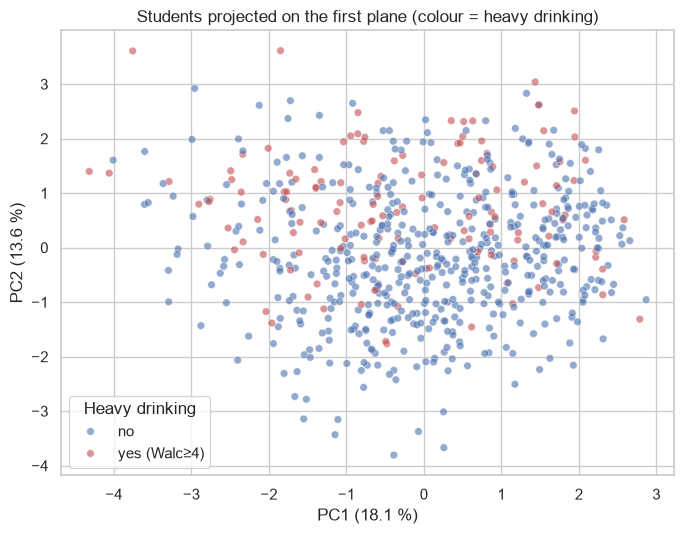

In [13]:
proj = pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"])
proj["Heavy drinking"] = np.where(por["high"].values == 1, "yes (Walc≥4)", "no")

plt.figure(figsize=(7, 5.5))
sns.scatterplot(data=proj, x="PC1", y="PC2", hue="Heavy drinking",
                palette={"yes (Walc≥4)": "#C44E52", "no": "#4C72B0"},
                alpha=0.6, s=30)
plt.xlabel(f"PC1 ({var[0]:.1f} %)"); plt.ylabel(f"PC2 ({var[1]:.1f} %)")
plt.title("Students projected on the first plane (colour = heavy drinking)")
plt.tight_layout(); plt.show()

## 5. Preparing the prediction

We predict `high` from the **social, family and behavioural profile**. We **deliberately exclude**:
- the alcohol variables themselves (`Dalc`, `Walc`), since they define the target;
- the grades (`G1`, `G2`, `G3`), since they are a school *outcome*, not a driver of drinking.

Preprocessing (scaling of numerical variables + one-hot encoding of categorical ones) is wrapped in a `Pipeline`: it is fitted only on the training data in each cross-validation fold (no leakage).

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

def make_Xy(df):
    """X = social/family/behavioural profile (no alcohol, no grades), y = heavy drinking."""
    return df[NUM + CAT].copy(), df["high"].copy()

X, y = make_Xy(por)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT),
])

def pipe(model):
    """Chain preprocessing + model (prevents any data leakage in cross-validation)."""
    return Pipeline([("prep", preprocess), ("model", model)])

print("X:", X.shape, "| positives (heavy drinking):", int(y.sum()), "out of", len(y))

X: (649, 28) | positives (heavy drinking): 132 out of 649


## 6. Classification models

We compare classic methods:
- **LDA** / **QDA**: discriminant analysis (linear vs quadratic boundary);
- **Logistic regression**: linear, very interpretable;
- **KNN**: non-parametric, neighbourhood-based;
- a **baseline** (always predict the majority class) as a reference point.

Evaluation uses **stratified 5-fold cross-validation** (stratification keeps the ~20% of positives in every fold).

In [15]:
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                            QuadraticDiscriminantAnalysis)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "LDA":                 LinearDiscriminantAnalysis(),
    "QDA":                 QuadraticDiscriminantAnalysis(reg_param=0.1),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "KNN (k=15)":          KNeighborsClassifier(n_neighbors=15),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
scoring = ["accuracy", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    cvres = cross_validate(pipe(model), X, y, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 "accuracy": cvres["test_accuracy"].mean(),
                 "F1":       cvres["test_f1"].mean(),
                 "AUC":      cvres["test_roc_auc"].mean()})

results = pd.DataFrame(rows).set_index("model").sort_values("AUC", ascending=False)
results.round(3)

,accuracy,F1,AUC
model,,,
LDA,0.829,0.512,0.817
Logistic regression,0.840,0.521,0.816
QDA,0.794,0.377,0.724
KNN (k=15),0.803,0.118,0.717
Baseline (majority class),0.797,0.000,0.500


### 6.2 ROC curves

The ROC curve shows the trade-off between true positives and false positives at every decision threshold. The further the curve is from the diagonal, the better the model.

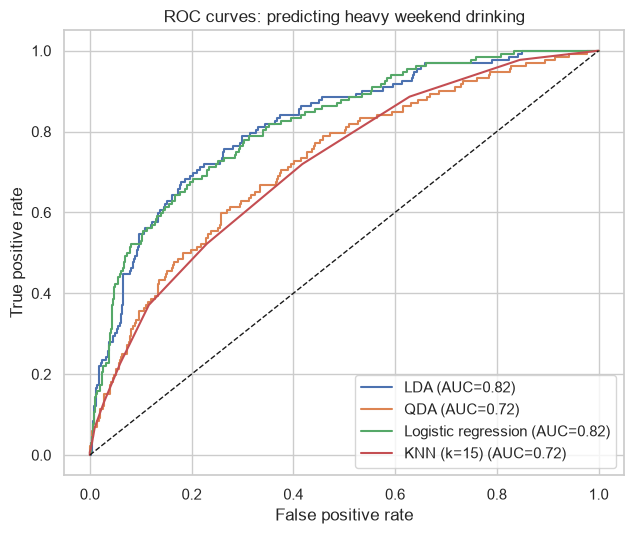

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(6.5, 5.5))
for name, model in models.items():
    if "Baseline" in name:
        continue
    proba = cross_val_predict(pipe(model), X, y, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, proba):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves: predicting heavy weekend drinking")
plt.legend(); plt.tight_layout(); plt.show()

## 7. Gradient boosting and skrub

Do tree-based models do better than the linear ones? We add three pipelines, evaluated with **the same `StratifiedKFold`** (5 folds, same seed) and the same metrics:
- `HistGradientBoostingClassifier` inside the **same hand-written preprocessing** as above;
- skrub's **`TableVectorizer`** + `HistGradientBoostingClassifier`: the vectorizer detects column types and encodes them by itself, so there is no list of columns to maintain;
- **`skrub.tabular_pipeline("classifier")`**: skrub's default pipeline (a `TableVectorizer` that keeps low-cardinality columns as categories + a gradient boosting that handles them natively).

The table also reports the standard deviation of the AUC across the 5 folds, to see whether differences are larger than the fold-to-fold noise.

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
import skrub

new_models = {
    "Gradient boosting (same preprocessing)": pipe(HistGradientBoostingClassifier(random_state=RNG)),
    "skrub TableVectorizer + gradient boosting": make_pipeline(
        skrub.TableVectorizer(), HistGradientBoostingClassifier(random_state=RNG)),
    "skrub tabular_pipeline('classifier')": skrub.tabular_pipeline("classifier"),
}

# Every model, old and new, scored with the same folds and metrics
all_models = {name: pipe(model) for name, model in models.items()} | new_models

rows = []
for name, estimator in all_models.items():
    cvres = cross_validate(estimator, X, y, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 "accuracy": cvres["test_accuracy"].mean(),
                 "F1":       cvres["test_f1"].mean(),
                 "AUC":      cvres["test_roc_auc"].mean(),
                 "AUC std":  cvres["test_roc_auc"].std()})

final = pd.DataFrame(rows).set_index("model").sort_values("AUC", ascending=False)
final.round(3)

,accuracy,F1,AUC,AUC std
model,,,,
LDA,0.829,0.512,0.817,0.037
Logistic regression,0.840,0.521,0.816,0.035
Gradient boosting (same preprocessing),0.817,0.467,0.806,0.031
skrub TableVectorizer + gradient boosting,0.817,0.467,0.806,0.031
skrub tabular_pipeline('classifier'),0.818,0.455,0.803,0.026
QDA,0.794,0.377,0.724,0.061
KNN (k=15),0.803,0.118,0.717,0.044
Baseline (majority class),0.797,0.000,0.500,0.000


**Interpretation.** Gradient boosting does not beat the linear models here. Its mean AUC (0.806) is about 0.01 below logistic regression (0.816) and its F1 is lower (0.467 vs 0.521), but the AUC gap is smaller than the fold-to-fold standard deviation (about 0.03), so the fair reading is "no gain" rather than "worse". This is plausible: with 649 rows and only 132 positives, and a signal carried mostly by a few main effects (sex, going out, study time), an ensemble of trees with default settings has little to add over a linear model and more room to overfit. skrub did not change the scores: `TableVectorizer` + gradient boosting gives exactly the same numbers as the hand-written pipeline (trees ignore scaling, and both one-hot encode the same columns), and `tabular_pipeline` lands at a similar AUC. What it changed is the amount of code: no column lists to write and keep in sync with the data.

## 8. Interpretation: risk factors

Logistic regression gives each variable a **signed coefficient** (on standardised variables, so they are comparable). A positive coefficient increases the probability of heavy drinking. The **odds ratio** = exp(coefficient) reads as a multiplier of the *odds* of heavy drinking.

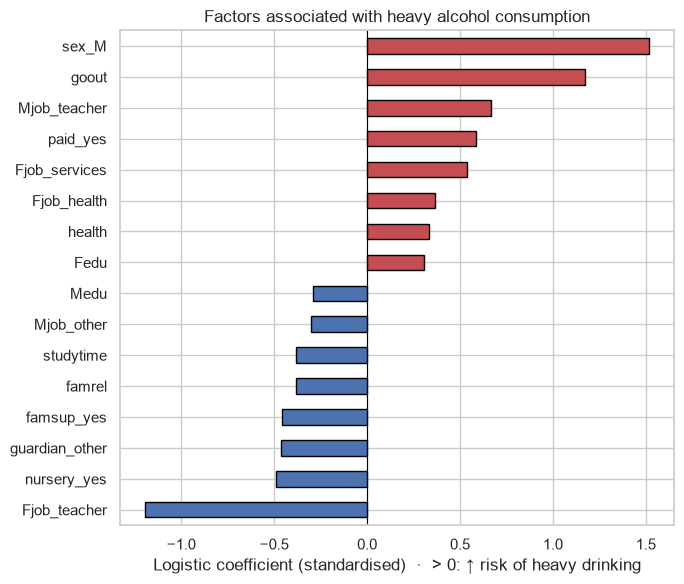

Odds ratios (exp of the coefficient) of the variables shown:
sex_M             4.55
goout             3.24
Mjob_teacher      1.95
paid_yes          1.80
Fjob_services     1.71
Fjob_health       1.44
health            1.40
Fedu              1.36
Medu              0.75
Mjob_other        0.74
studytime         0.68
famrel            0.68
famsup_yes        0.63
guardian_other    0.63
nursery_yes       0.61
Fjob_teacher      0.30


In [18]:
# Refit the logistic regression on the full dataset to read its coefficients
logreg = pipe(LogisticRegression(max_iter=1000)).fit(X, y)

feature_names = logreg.named_steps["prep"].get_feature_names_out()
coef_s = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names)
coef_s.index = coef_s.index.str.replace(r"^(num|cat)__", "", regex=True)

ordered = coef_s.sort_values()
top = pd.concat([ordered.head(8), ordered.tail(8)])   # 8 most protective + 8 most risky

plt.figure(figsize=(7, 6))
colors = ["#C44E52" if c > 0 else "#4C72B0" for c in top.values]
top.plot(kind="barh", color=colors, edgecolor="black")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Logistic coefficient (standardised)  ·  > 0: ↑ risk of heavy drinking")
plt.title("Factors associated with heavy alcohol consumption")
plt.tight_layout(); plt.show()

print("Odds ratios (exp of the coefficient) of the variables shown:")
print(np.exp(top).sort_values(ascending=False).round(2).to_string())

In [19]:
# Comparison: coefficients of the LDA discriminant function (same reading of the sign)
lda = pipe(LinearDiscriminantAnalysis()).fit(X, y)
lda_coef = pd.Series(lda.named_steps["model"].coef_[0], index=feature_names)
lda_coef.index = lda_coef.index.str.replace(r"^(num|cat)__", "", regex=True)

print("Top 10 variables of the LDA discriminant function (|coef|):")
print(lda_coef.reindex(lda_coef.abs().sort_values(ascending=False).index)
              .head(10).round(2).to_string())

Top 10 variables of the LDA discriminant function (|coef|):
sex_M             1.81
Fjob_teacher     -1.53
goout             1.19
paid_yes          0.80
Mjob_teacher      0.79
guardian_other   -0.67
nursery_yes      -0.54
famsup_yes       -0.45
famrel           -0.42
Fjob_services     0.41


## 9. Robustness of the conclusions

Do the results hold if we change the analysis choices? We rerun the evaluation (mean AUC, 5-fold CV) while varying:
- the target **threshold** (`Walc` ≥ 3 instead of 4);
- the **sample** (maths instead of Portuguese);
- the **features**: we **remove `goout`** to check that sociability carries the signal (the AUC should then drop).

In [20]:
def evaluate(df, num=NUM, cat=CAT, threshold=4, cv=cv):
    """Mean AUC (5-fold CV) of each model for a given dataset / threshold / feature set."""
    d = df.copy()
    d["high"] = (d["Walc"] >= threshold).astype(int)
    Xd, yd = d[num + cat], d["high"]
    prep = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat),
    ])
    out = {}
    for name, model in models.items():
        if "Baseline" in name:
            continue
        pl = Pipeline([("prep", prep), ("model", model)])
        out[name] = cross_validate(pl, Xd, yd, cv=cv, scoring=["roc_auc"])["test_roc_auc"].mean()
    return pd.Series(out, name="AUC")

robustness = pd.DataFrame({
    "Portuguese, Walc≥4 (reference)": evaluate(por),
    "Portuguese, Walc≥3":             evaluate(por, threshold=3),
    "Maths, Walc≥4":                  evaluate(mat),
    "Portuguese, without 'goout'":    evaluate(por, num=[c for c in NUM if c != "goout"]),
})
robustness.round(3)

,"Portuguese, Walc≥4 (reference)","Portuguese, Walc≥3","Maths, Walc≥4","Portuguese, without 'goout'"
LDA,0.817,0.733,0.797,0.739
QDA,0.724,0.686,0.731,0.657
Logistic regression,0.816,0.735,0.800,0.735
KNN (k=15),0.717,0.679,0.736,0.653


## 10. (Optional) A typology of drinking behaviour

To go further, we build a **typology** with *k*-means on a few drinking and sociability variables, to bring out **typical profiles**. Here students are grouped by their **drinking behaviour**, not by their family background.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = ["Dalc", "Walc", "goout", "freetime"]
Z = StandardScaler().fit_transform(por[features])

print("Choosing the number of groups (silhouette, higher = better):")
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=RNG).fit(Z)
    print(f"  k={k}: {silhouette_score(Z, km.labels_):.3f}")

Choosing the number of groups (silhouette, higher = better):
  k=2: 0.337
  k=3: 0.273
  k=4: 0.256
  k=5: 0.262


In [22]:
km = KMeans(n_clusters=3, n_init=10, random_state=RNG).fit(Z)

# Group labels based on their mean profiles (see the table below)
LABELS = {0: "outgoing", 1: "low-key", 2: "regular drinker"}
por_typ = por.copy()
por_typ["profile"] = km.labels_
por_typ["type"] = por_typ["profile"].map(LABELS)

profiles = por_typ.groupby("profile")[features + ["high"]].mean().round(2)
profiles.insert(0, "type", pd.Series(LABELS))
profiles["size"] = por_typ["profile"].value_counts().sort_index()
profiles

,type,Dalc,Walc,goout,freetime,high,size
profile,,,,,,,
0,outgoing,1.15,1.95,3.98,3.93,0.07,206
1,low-key,1.17,1.80,2.36,2.59,0.05,322
2,regular drinker,3.00,4.13,4.03,3.47,0.83,121


### 10.2 The three profiles on a plane

The four clustering variables are projected on a factor plane (2D PCA) to check consistency: each colour is a group, and the crosses mark the labelled **centroids**. The three profiles should form distinct areas.

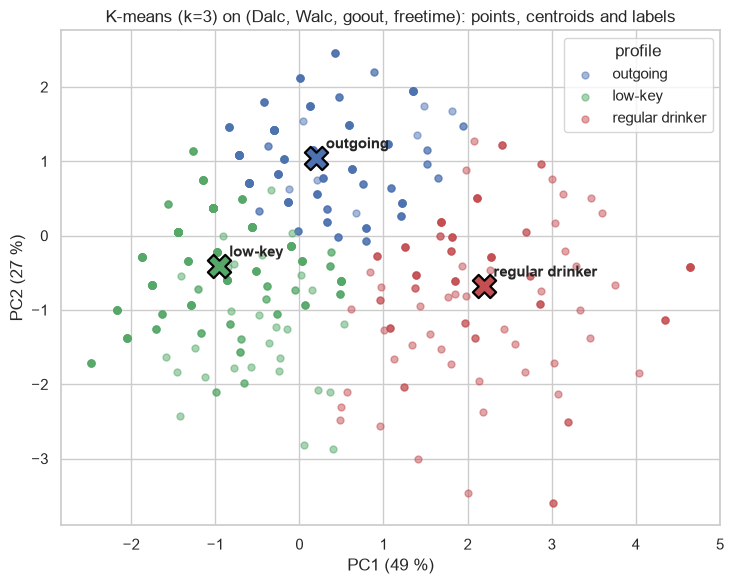

In [23]:
pca_km = PCA(n_components=2, random_state=RNG)
pts = pca_km.fit_transform(Z)
centroids = pca_km.transform(km.cluster_centers_)   # centroids in the same plane
var_km = pca_km.explained_variance_ratio_ * 100

palette = {"low-key": "#55A868", "outgoing": "#4C72B0", "regular drinker": "#C44E52"}
plt.figure(figsize=(7.5, 6))
for i, lab in LABELS.items():
    m = por_typ["type"].values == lab
    plt.scatter(pts[m, 0], pts[m, 1], s=25, alpha=0.5, color=palette[lab], label=lab)
    plt.scatter(*centroids[i], marker="X", s=280, color=palette[lab],
                edgecolor="black", linewidth=1.6, zorder=5)
    plt.annotate(lab, centroids[i], xytext=(7, 7), textcoords="offset points",
                 fontsize=11, fontweight="bold")
plt.xlabel(f"PC1 ({var_km[0]:.0f} %)"); plt.ylabel(f"PC2 ({var_km[1]:.0f} %)")
plt.title("K-means (k=3) on (Dalc, Walc, goout, freetime): points, centroids and labels")
plt.legend(title="profile"); plt.tight_layout(); plt.show()

## 11. Summary and conclusions

**1. Who drinks?** Heavy weekend drinking mostly concerns a **sociable, male** profile: `sex` and `goout` (going out) are the strongest risk factors; study time works in the opposite direction.

**2. Weekdays ≠ weekend.** Weekday drinking (`Dalc`) is rare (about 70% of students at level 1); weekend drinking (`Walc`) is much more common and more social. The two are related (Spearman correlation 0.61) but distinct.

**3. Drinking as part of a lifestyle.** Heavy drinking can be predicted reasonably well from the social and behavioural profile alone (best cross-validated AUC 0.82 with LDA and logistic regression, against 0.50 for the baseline), and the PCA places it on a **sociability** axis. Removing `goout` drops the AUC to about 0.74, which confirms that going out carries much of the signal.

**4. Model choice.** Gradient boosting, with or without skrub, does not improve on the linear models on this small table (AUC 0.80 to 0.81). The linear models are as good and easier to explain.

**Limitations.** Ordinal variables treated as numerical; self-reported survey data; modest sample (n = 649); a target that depends on a threshold (partly addressed by the robustness checks in section 9); associations, not causal effects.